# 04 · Dynamic Buffer Gas Model

Alkali vapour cells are often filled with a noble gas or N₂ to slow atomic
diffusion and reduce wall-collision depolarisation.  The buffer gas causes:

- **Pressure broadening** — additional Lorentzian linewidth
- **Pressure shift** — displacement of resonance frequency

Both depend on temperature and pressure.  ElecSus v4 computes them
automatically from the `BufferGas`, `BufferPressure`, and `BufferTemp_fill`
parameters, using the data of Pitz et al. (2014).

Validated against Alqarni et al. 2025 (K D1 / Ne).


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate() returns complex arrays; for real-valued outputs (transmission,
# Stokes parameters) the imaginary part is ~0. Silence the cast-to-real warning
# when plotting - take .real explicitly if you need the numeric values.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-2000, 2000, 800)  # MHz


## K D1 — Ne buffer gas, varying pressure

The K D1 line is a clean two-feature spectrum at zero field, making it ideal
for demonstrating pressure broadening.  The broadening rate for K/Ne is
~17 MHz/Torr at 300 K (Pitz et al. 2014).

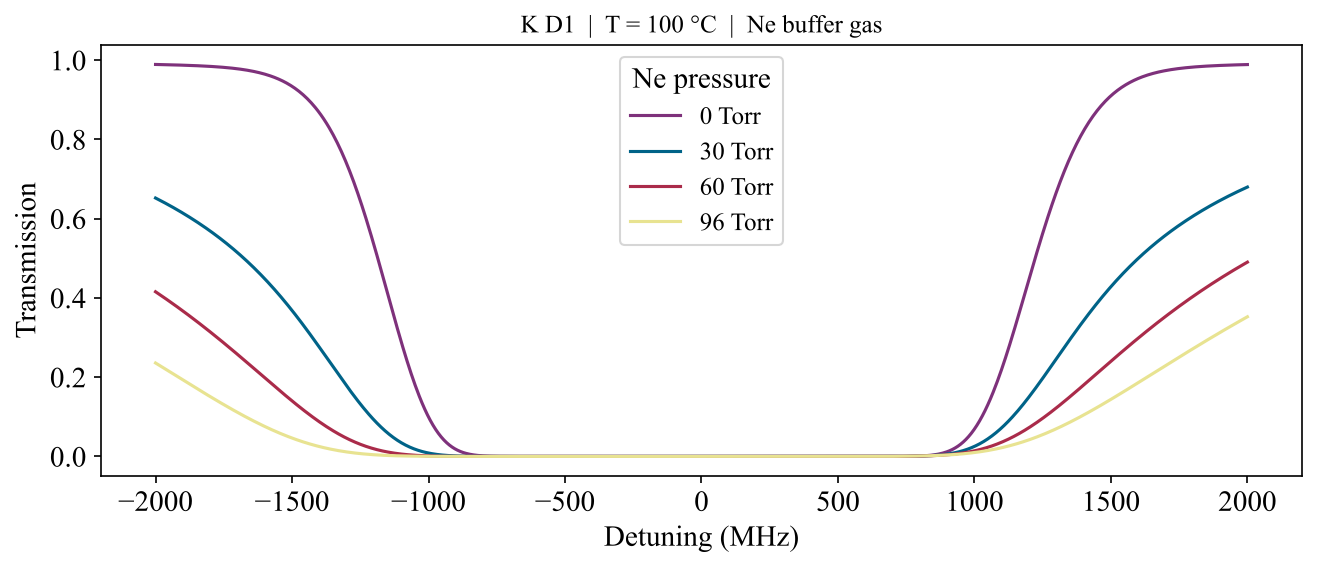

In [2]:
p_base = {
    'Elem':'K', 'Dline':'D1', 'T':100., 'lcell':75e-3, 'Bfield':0,
    'BufferGas':'Ne', 'BufferTemp_fill':293.15,
}

pressures = [0, 30, 60, 96]
fig, ax = plt.subplots(figsize=(9, 4))
for P in pressures:
    p = {**p_base, 'BufferPressure': P} if P > 0 else {'Elem':'K','Dline':'D1','T':100.,'lcell':75e-3,'Bfield':0}
    [S0] = em.calculate(det, [1,0,0], p, outputs=['S0'])
    ax.plot(det, S0, label=f'{P} Torr')
ax.set(xlabel='Detuning (MHz)', ylabel='Transmission',
       title='K D1  |  T = 100 °C  |  Ne buffer gas')
ax.legend(title='Ne pressure')
plt.tight_layout()


## Frequency shift with pressure

The buffer gas also shifts the line centre. For K D1 / Ne the shift coefficient
is negative, a red shift: the line moves to lower frequency, by about 1.5 MHz
per Torr of fill pressure at 100 °C. We can track the shift by fitting the peak
absorption position.

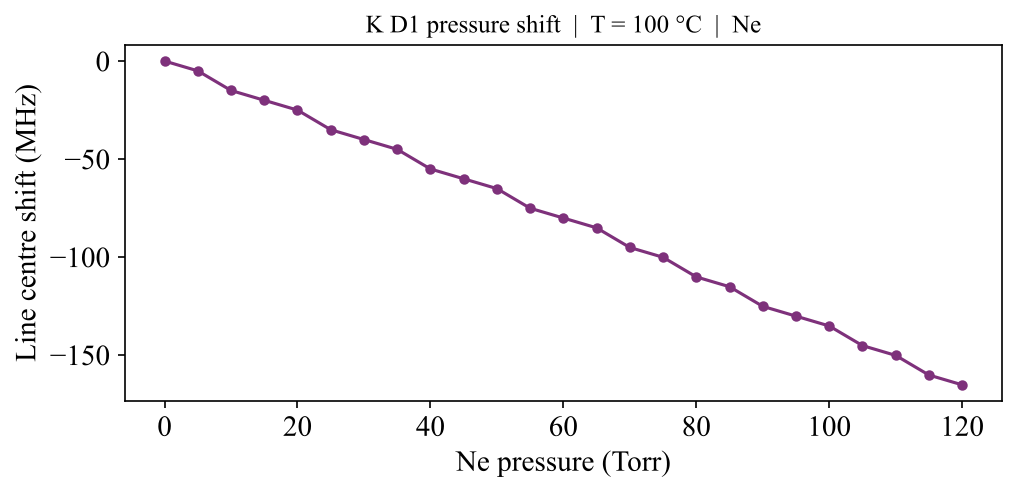

In [3]:
pressures_fine = np.linspace(0, 120, 25)
det_fine = np.linspace(-1500, 1500, 600)
shifts = []
for P in pressures_fine:
    if P == 0:
        p = {'Elem':'K','Dline':'D1','T':100.,'lcell':75e-3,'Bfield':0}
    else:
        p = {'Elem':'K','Dline':'D1','T':100.,'lcell':75e-3,'Bfield':0,
             'BufferGas':'Ne','BufferPressure':P,'BufferTemp_fill':293.15}
    [S0] = em.calculate(det_fine, [1,0,0], p, outputs=['S0'])
    # track the leftmost absorption minimum
    shifts.append(det_fine[np.argmin(S0.real[:len(S0)//2])])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(pressures_fine, np.array(shifts) - shifts[0], 'o-', ms=4)
ax.set(xlabel='Ne pressure (Torr)', ylabel='Line centre shift (MHz)',
       title='K D1 pressure shift  |  T = 100 °C  |  Ne')
plt.tight_layout()


## Different buffer gases

ElecSus supports He, Ne, Ar, Kr, Xe, N₂ and several others.  The broadening
and shift coefficients differ substantially between species.

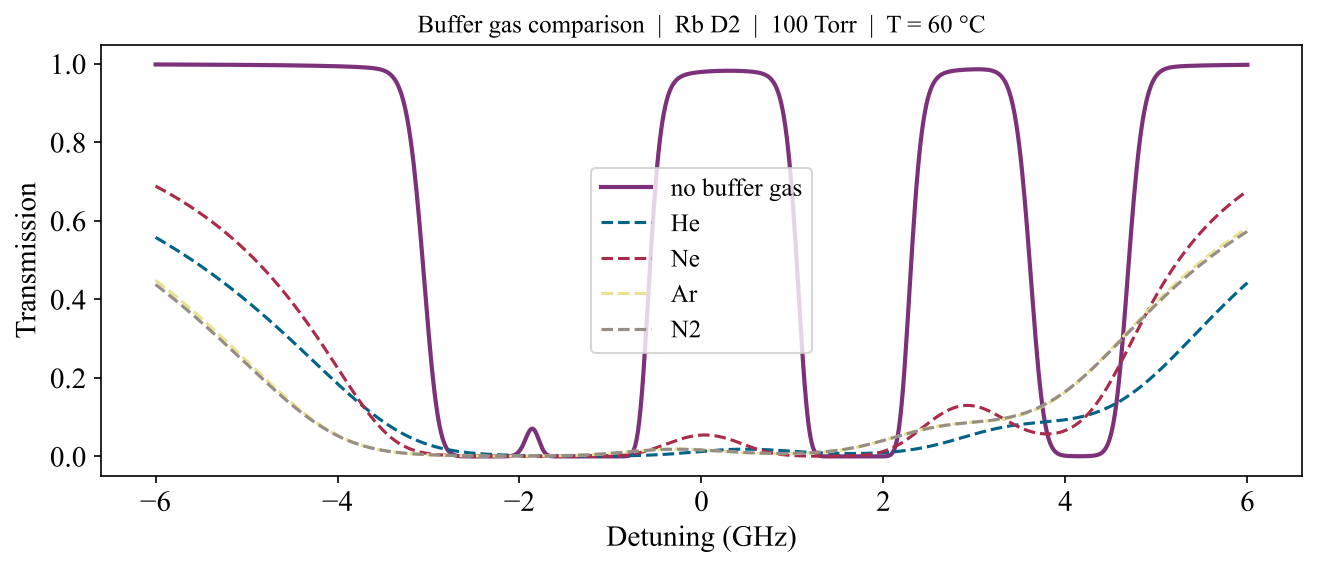

In [4]:
p_cmp = {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':0,
          'BufferPressure':100.,'BufferTemp_fill':293.15}
det_rb = np.linspace(-6000, 6000, 800)

fig, ax = plt.subplots(figsize=(9, 4))
[S0_no] = em.calculate(det_rb, [1,0,0],
                        {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3},
                        outputs=['S0'])
ax.plot(det_rb/1e3, S0_no, label='no buffer gas', lw=2)
for gas in ['He', 'Ne', 'Ar', 'N2']:
    [S0] = em.calculate(det_rb, [1,0,0], {**p_cmp,'BufferGas':gas}, outputs=['S0'])
    ax.plot(det_rb/1e3, S0, label=gas, ls='--')
ax.set(xlabel='Detuning (GHz)', ylabel='Transmission',
       title='Buffer gas comparison  |  Rb D2  |  100 Torr  |  T = 60 °C')
ax.legend()
plt.tight_layout()


## Temperature dependence of broadening

In a sealed cell the buffer gas density is fixed, so the broadening depends on the
cell temperature T only through the collision velocity:
Γ(T) = γ₀ × P_eq × (T/T₀)^0.5, with P_eq = P_fill × T₀/T_fill the pressure the gas
would have at the reference temperature T₀ = 328 K, and γ₀ the rate in MHz/Torr at T₀
(the literature). The pressure in the cell grows as T/T_fill, and the
rate per Torr falls as T^(−0.5), so the broadening grows as √T.

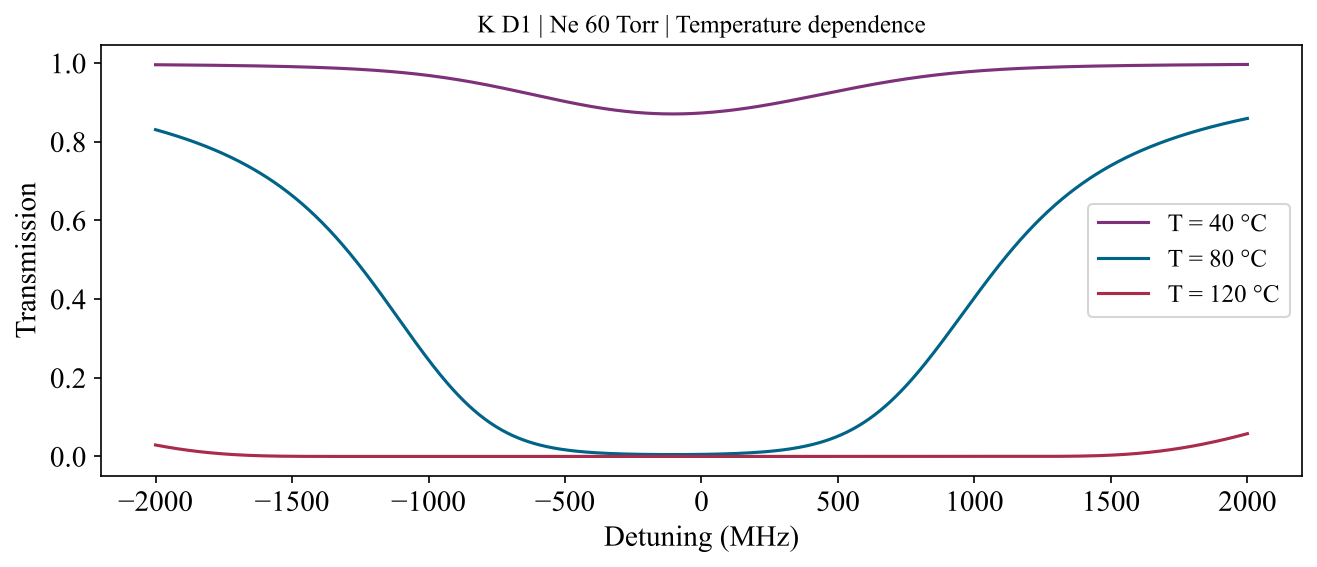

In [5]:
temps = [40, 80, 120]
fig, ax = plt.subplots(figsize=(9, 4))
for T in temps:
    p = {'Elem':'K','Dline':'D1','T':T,'lcell':75e-3,'Bfield':0,
         'BufferGas':'Ne','BufferPressure':60.,'BufferTemp_fill':293.15}
    [S0] = em.calculate(det, [1,0,0], p, outputs=['S0'])
    ax.plot(det, S0, label=f'T = {T} °C')
ax.set(xlabel='Detuning (MHz)', ylabel='Transmission',
       title='K D1 | Ne 60 Torr | Temperature dependence')
ax.legend()
plt.tight_layout()
